I/Prétraitement et analyse exploratoire

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.max_columns", 50)

1.Chargement des données

In [2]:
df = pd.read_csv("../data/raw/data.csv")

print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [4]:
print(list(df.columns))
print(df["diagnosis"].value_counts())

['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
diagnosis
B    357
M    212
Name: count, dtype: int64


2.Traitement de la colonne parasite
La colonne `Unnamed: 32` est entièrement vide (569 valeurs manquantes sur 569).
On vérifie qu'elle ne contient aucune donnée, puis on la supprime. La colonne `id` est exclue des analyses et le diagnostic est codé B = 0, M = 1.

In [5]:
col = "Unnamed: 32"
print("Valeurs non nulles   :", df[col].notna().sum())
print("Valeurs manquantes   :", df[col].isna().sum(), "sur", len(df))
print("Valeurs distinctes   :", df[col].nunique(dropna=True))

Valeurs non nulles   : 0
Valeurs manquantes   : 569 sur 569
Valeurs distinctes   : 0


In [6]:
assert df[col].isna().all(), "La colonne contient des données : ne pas la supprimer !"

df_clean = df.drop(columns=[col])
print("Avant :", df.shape, "| Après :", df_clean.shape)

Avant : (569, 33) | Après : (569, 32)


In [7]:
print("id tous uniques :", df_clean["id"].is_unique)

df_clean["target"] = df_clean["diagnosis"].map({"B": 0, "M": 1})
print("Valeurs non codées :", df_clean["target"].isna().sum())

feature_cols = [c for c in df_clean.columns if c not in ("id", "diagnosis", "target")]
print("Nombre de variables :", len(feature_cols))

id tous uniques : True
Valeurs non codées : 0
Nombre de variables : 30


3.Audit de qualité des données
Contrôle des valeurs manquantes, des doublons, des valeurs impossibles et des
valeurs aberrantes (règle de l'IQR).

In [8]:
manquantes = df_clean[feature_cols + ["diagnosis"]].isna().sum()
print("Total de valeurs manquantes :", manquantes.sum())
print("Variables concernées :", (manquantes > 0).sum())

Total de valeurs manquantes : 0
Variables concernées : 0


In [9]:
print("Lignes entièrement dupliquées         :", df_clean.duplicated().sum())
print("Doublons sur les 30 mesures (sans id) :", df_clean.duplicated(subset=feature_cols).sum())
print("id dupliqués                          :", df_clean["id"].duplicated().sum())

Lignes entièrement dupliquées         : 0
Doublons sur les 30 mesures (sans id) : 0
id dupliqués                          : 0


In [10]:
print("Valeurs négatives :", (df_clean[feature_cols] < 0).sum().sum())

zeros = (df_clean[feature_cols] == 0).sum()
print("\nVariables contenant des zéros :")
print(zeros[zeros > 0])

Valeurs négatives : 0

Variables contenant des zéros :
concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


In [11]:
zero_cols = ["concavity_mean", "concave points_mean", "concavity_se",
             "concave points_se", "concavity_worst", "concave points_worst"]

lignes_zero = (df_clean[zero_cols] == 0).any(axis=1)
print("Patientes concernées :", lignes_zero.sum())
print(df_clean.loc[lignes_zero, "diagnosis"].value_counts())

# Sont-ce exactement les mêmes lignes pour les 6 variables ?
print("Mêmes lignes pour les 6 variables :",
      all(((df_clean[c] == 0) == (df_clean["concavity_mean"] == 0)).all() for c in zero_cols))

Patientes concernées : 13
diagnosis
B    13
Name: count, dtype: int64
Mêmes lignes pour les 6 variables : True


In [12]:
Q1 = df_clean[feature_cols].quantile(0.25)
Q3 = df_clean[feature_cols].quantile(0.75)
IQR = Q3 - Q1

masque = (df_clean[feature_cols] < Q1 - 1.5 * IQR) | (df_clean[feature_cols] > Q3 + 1.5 * IQR)

resume = pd.DataFrame({
    "nb_outliers": masque.sum(),
    "pct": (masque.mean() * 100).round(1)
}).sort_values("nb_outliers", ascending=False)

print(resume.head(10))
print("\nIndividus avec au moins un outlier :", masque.any(axis=1).sum(), "sur", len(df_clean))

                         nb_outliers   pct
area_se                           65  11.4
radius_se                         38   6.7
perimeter_se                      38   6.7
area_worst                        35   6.2
smoothness_se                     30   5.3
fractal_dimension_se              28   4.9
compactness_se                    28   4.9
symmetry_se                       27   4.7
area_mean                         25   4.4
fractal_dimension_worst           24   4.2

Individus avec au moins un outlier : 171 sur 569


In [13]:
out_par_classe = masque.groupby(df_clean["diagnosis"]).sum().sum(axis=1)
print("Outliers par classe (total sur les 30 variables) :")
print(out_par_classe)

Outliers par classe (total sur les 30 variables) :
diagnosis
B    139
M    469
dtype: int64


In [14]:
nb_out_indiv = masque.sum(axis=1)
print(nb_out_indiv.groupby(df_clean["diagnosis"]).agg(["mean", "median", "max"]).round(2))

print("\nPart des individus avec au moins un outlier :")
print((nb_out_indiv > 0).groupby(df_clean["diagnosis"]).mean().round(3))

           mean  median  max
diagnosis                   
B          0.39     0.0   10
M          2.21     1.0   18

Part des individus avec au moins un outlier :
diagnosis
B    0.160
M    0.538
dtype: float64


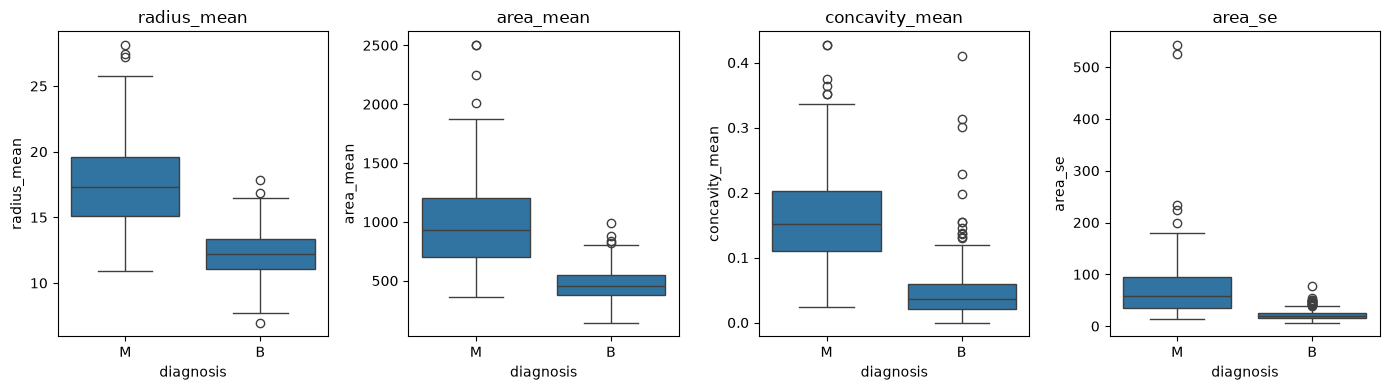

In [15]:
os.makedirs("../reports/figures", exist_ok=True)

vars_ex = ["radius_mean", "area_mean", "concavity_mean", "area_se"]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, v in zip(axes, vars_ex):
    sns.boxplot(data=df_clean, x="diagnosis", y=v, ax=ax)
    ax.set_title(v)
plt.tight_layout()
plt.savefig("../reports/figures/boxplots_outliers.png", dpi=150, bbox_inches="tight")
plt.show()